# Fresnel disk-pair intensity asymmetry — 2D tilt grid

Grid companion to `create_paper_figs_disks_intensity_MORE_DISKS.ipynb`; same styling and conventions.

- Exact box mirror `(H+1-hi, H+1-lo)` via `kikuchi_com.mirror_box` (was `(H-hi, H-lo)`).
- Asymmetry normalised, `(b1-b2)/(b1+b2) x 100`, so it is a real percentage and comparable
  between materials (was raw summed counts), and all heatmaps share one colour scale.
- Polar alignment is one flag, `flip_polar`, replacing `sign_flip` + `tilt_flip`. Mirroring
  through the plane perpendicular to P reverses rotations about y but not about x:
  `v_aligned(ty, tx) = -v(-ty, tx)`. That is exactly what the old flag pair did.
- Patterns shown on an inverse-angstrom extent with a scale bar; heatmap extents padded by half
  a step, since the tilt values are cell centres.


In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import PowerNorm

plt.style.use("paper")   # ~/.config/matplotlib/stylelib

sys.path.insert(0, "..")
from polarisation_direction import P_REVERSED
from kikuchi_com import mirror_box, BORACITE_EXTENT, DISK_LATTICE, disk_row_box, reflection

FOV_INVA = 1.75    # half-width displayed, inverse angstrom, common to all three
SCALEBAR = 1.0     # inverse angstrom

# lighter tints of the stylesheet hues, readable on the dark pattern
LABEL_COLOUR = {"100": "#9ca2bb", "200": "#ecbc9c", "300": "#b2bfb0"}
WIDTH_LABEL = {"1x1": r"1$\times$1", "1x3": r"1$\times$3"}
FG, ZERO = "black", "black"

GAMMA, PMIN, PMAX = 0.3, 0.5, 99.8


In [2]:
# ── Per-material configuration ───────────────────────────────────────────────
# boxes: (order, width) -- box1 is built by kikuchi_com.disk_row_box on the detected disk
# lattice (DISK_LATTICE: spacing, half-width); the partner is its exact mirror.
# Rows of the figure follow this order, so keep it aligned across materials.
#
# flip_polar: BTO's CIF is polarised opposite to PTO's; boracite is flipped to match
# PTO in this low-angle regime (see the caveat in the 1D disk notebook).

# Disk data: the 4096-grid, full-detector Kikuchi grid sims (9 x 9 tilts, +-0.6 deg, 0.15 deg step).
# The dedicated disk grids (data/grids/disks, +-0.05 deg) used a 1024 grid, which is not converged.
MATERIALS = {
    "PTO": dict(
        formula=r"PbTiO$_3$", abbr="PTO", path="../data/grids/kikuchi/PTO_kikuchi_grid.npz",
        cell=(3.9423, 3.8862), nrep=30, flip_polar=False,
        boxes=[("200", "1x1"),
               ("200", "1x3"),
               ("300", "1x1"),
               ("300", "1x3")]),
    "BTO": dict(
        formula=r"BaTiO$_3$", abbr="BTO", path="../data/grids/kikuchi/BTO_kikuchi_grid.npz",
        cell=(4.0230, 3.9905), nrep=30, flip_polar=True,
        boxes=[("200", "1x1"),
               ("200", "1x3"),
               ("300", "1x1"),
               ("300", "1x3")]),
    "Boracite": dict(
        formula=r"Cu$_3$B$_7$ClO$_{13}$", abbr="boracite",
        path="../data/grids/kikuchi/Boracite_kikuchi_grid.npz",
        cell=(17.1032, 17.1032), nrep=7,
        extent=(BORACITE_EXTENT, BORACITE_EXTENT),   # abTEM box, see kikuchi_com
        flip_polar=True,
        boxes=[("100", "1x1"),
               ("100", "1x3"),
               ("200", "1x1"),
               ("200", "1x3")]),
}

for cfg in MATERIALS.values():
    a0, a1 = cfg["cell"]; n = cfg["nrep"]
    e0, e1 = cfg.get("extent", (n*a0, n*a1))       # simulation box (A)
    cfg["kpp"] = (1.0 / e0, 1.0 / e1)               # inverse angstrom per pixel


In [3]:
def mirror_yx(box, H):
    """Exact mirror of a ((y_lo,y_hi),(x_lo,x_hi)) box through the centre H/2."""
    (lo, hi), (x0, x1) = box
    a, b, _, _ = mirror_box((lo, hi, x0, x1), H)
    return ((a, b), (x0, x1))


def asym(patterns, box1, box2):
    """Normalised intensity asymmetry, per cent: (b1 - b2) / (b1 + b2)."""
    (y1, y2), (x1, x2) = box1
    (Y1, Y2), (X1, X2) = box2
    b1 = patterns[..., y1:y2, x1:x2].sum(axis=(-2, -1))
    b2 = patterns[..., Y1:Y2, X1:X2].sum(axis=(-2, -1))
    return (b1 - b2) / (b1 + b2) * 100


def process(name, cfg):
    d = np.load(cfg["path"])
    p = d["diffraction_images"].astype(np.float64)     # (n_y, n_x, H, W)
    H, W = p.shape[-2:]
    ty, tx = d["tilt_y_values"].astype(float), d["tilt_x_values"].astype(float)
    assert np.all(np.diff(ty) > 0) and np.all(np.diff(tx) > 0)

    maps = {}
    for order, width in cfg["boxes"]:
        box1 = disk_row_box((H, W), *DISK_LATTICE[name], int(order[0]), int(width[-1]))
        box2 = mirror_yx(box1, H)
        v = raw = asym(p, box1, box2)
        if cfg["flip_polar"]:
            v = -v[::-1, :]            # -v(-ty, tx); ty grid is symmetric and ascending
        al = -raw[::-1, :] if P_REVERSED[name] else raw
        fin = raw if P_REVERSED[name] else -raw[::-1, :]   # P towards the top box
        maps[(order, width)] = dict(vals=v, raw=raw, aligned=al, final=fin, box1=box1, box2=box2)

    return dict(tilt_y=ty, tilt_x=tx, maps=maps,
                zero=p[int(np.argmin(abs(ty))), int(np.argmin(abs(tx)))], H=H, W=W)


results = {k: process(k, cfg) for k, cfg in MATERIALS.items()}
for k, r in results.items():
    for (o, w), m in r["maps"].items():
        print(f"{k:9s} {{{o}}} {w}: {m['vals'].min():+7.2f}..{m['vals'].max():+7.2f} %")


PTO       {200} 1x1:  -98.26.. +98.32 %
PTO       {200} 1x3:  -94.44.. +96.07 %
PTO       {300} 1x1:  -98.10.. +98.28 %
PTO       {300} 1x3:  -97.47.. +98.29 %
BTO       {200} 1x1:  -97.90.. +97.96 %
BTO       {200} 1x3:  -93.90.. +95.37 %
BTO       {300} 1x1:  -99.28.. +98.66 %
BTO       {300} 1x3:  -97.89.. +98.98 %
Boracite  {100} 1x1:  -78.30.. +97.16 %
Boracite  {100} 1x3:  -66.83.. +70.40 %
Boracite  {200} 1x1:  -97.09.. +97.59 %
Boracite  {200} 1x3:  -92.36.. +92.10 %


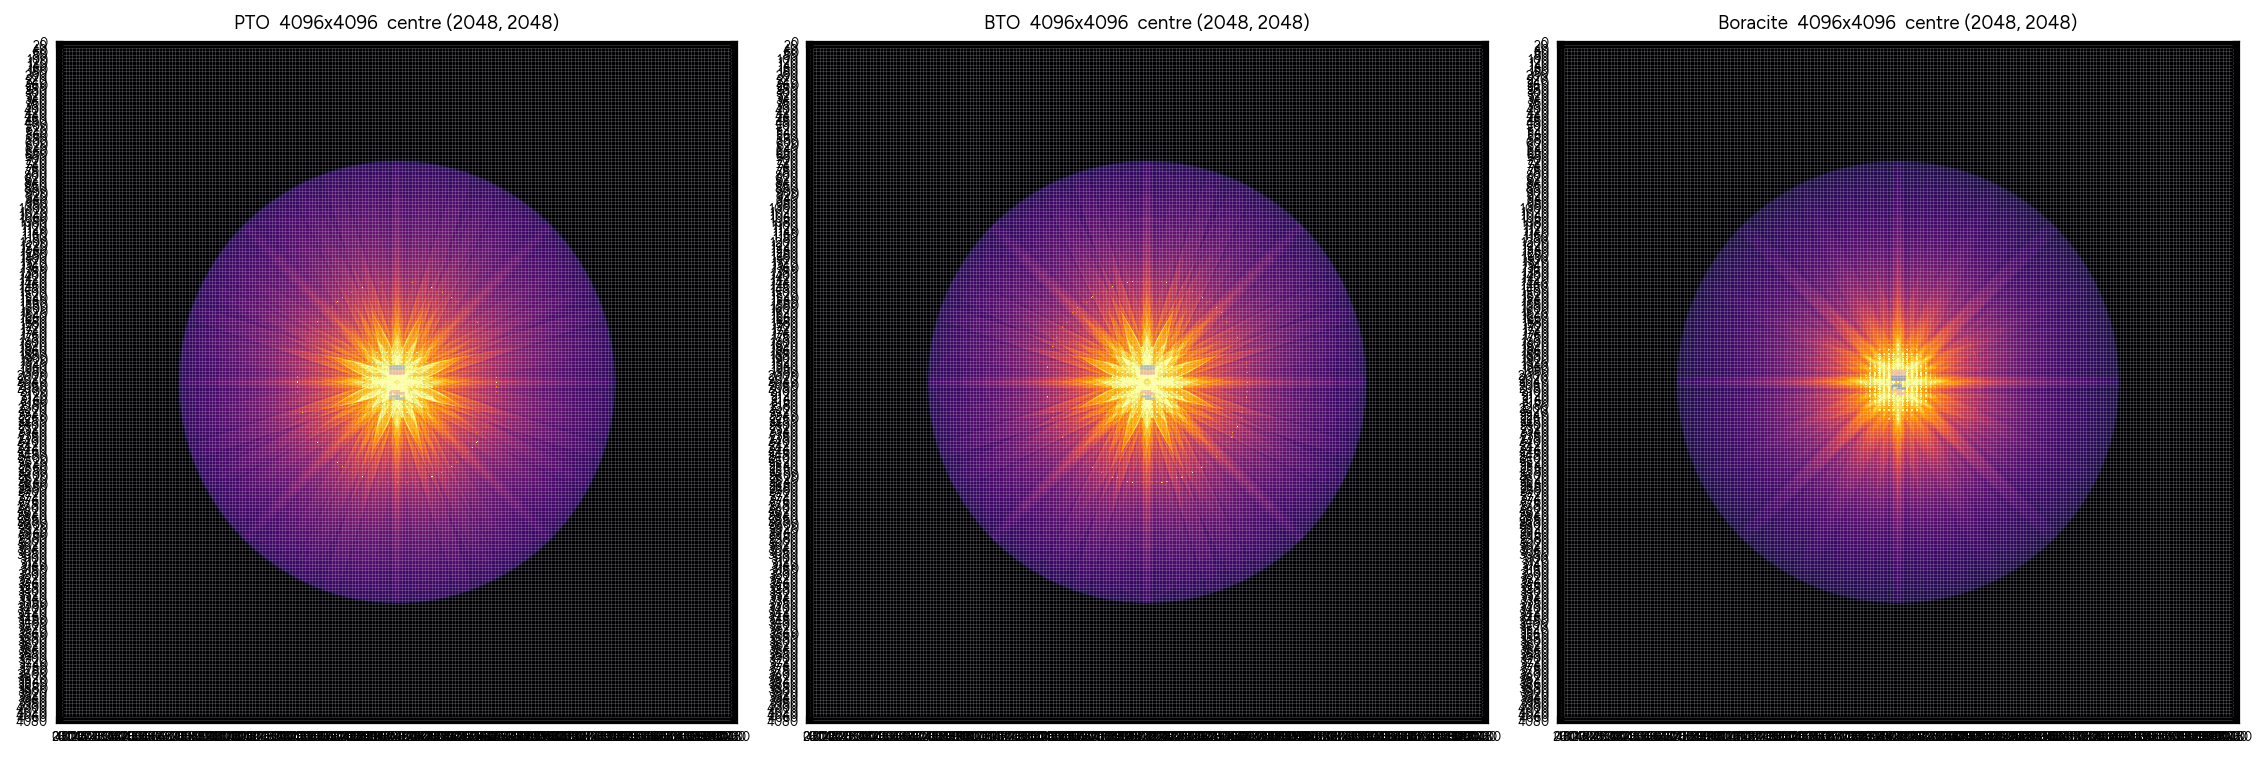

In [4]:
# ── Box placement check: axes on, gridded every 20 px ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, (name, res) in zip(axes, results.items()):
    img = res["zero"]
    vmin, vmax = np.percentile(img, [PMIN, PMAX])
    ax.imshow(img, cmap="inferno", origin="upper",
              norm=PowerNorm(gamma=GAMMA, vmin=vmin, vmax=vmax))
    for (order, width), m in res["maps"].items():
        for b, ls in ((m["box1"], "-"), (m["box2"], "--")):
            (lo, hi), (x0, x1) = b
            ax.add_patch(Rectangle((x0, lo), x1-x0, hi-lo, lw=1.2,
                                   edgecolor=LABEL_COLOUR[order], facecolor="none", linestyle=ls))
    ax.set_xticks(range(0, res["W"]+1, 20)); ax.set_yticks(range(0, res["H"]+1, 20))
    ax.tick_params(labelsize=6); ax.grid(True, color="white", alpha=0.2, lw=0.4)
    ax.set_title(f"{name}  {res['H']}x{res['W']}  centre ({res['H']//2}, {res['W']//2})", fontsize=9)
plt.show()


saved figures/disks_intensity_grid.{pdf,png}


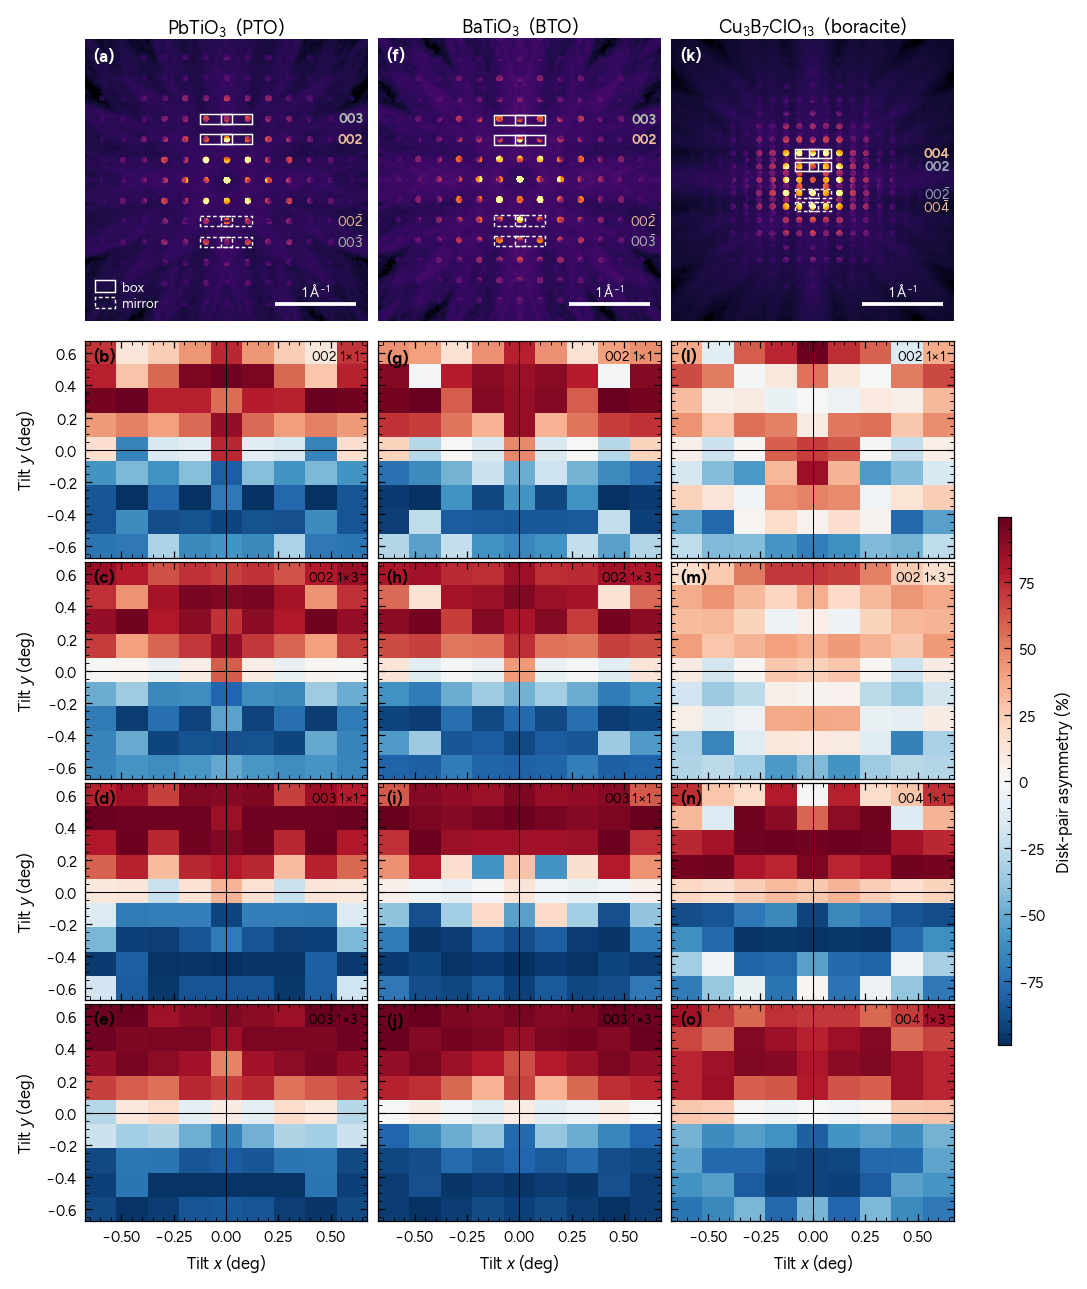

In [5]:
def grid_figure(raw=False, aligned=False, final=False):
    """raw=True: no polar alignment, tilt as simulated, 'unflipped_' prefix.
    aligned=True: every material mirrored to PTO's polarisation (P_REVERSED), 'aligned_' prefix.
    final=True: common polarisation frame with P towards the TOP box, i.e. PTO mirrored and
    BTO/boracite as simulated (both are built reversed relative to PTO); 'corrected_final/' prefix."""
    pre = "unflipped_" if raw else "aligned_" if aligned else "corrected_final/corrected_final_" if final else ""
    # ── Publication figure: 180 mm double column, styled by the paper stylesheet ─
    MM = 1 / 25.4
    mat_names = list(results)
    n_box = len(MATERIALS[mat_names[0]]["boxes"])

    fig, axes = plt.subplots(1 + n_box, 3, figsize=(180*MM, 215*MM),
                             gridspec_kw={"height_ratios": [1.45] + [1.0]*n_box},
                             layout="constrained")
    fig.get_layout_engine().set(h_pad=0.01, w_pad=0.01, hspace=0.015, wspace=0.03)
    letters = iter("abcdefghijklmno")

    vlim = max(np.abs(m["vals"]).max() for r in results.values() for m in r["maps"].values())


    def panel_label(ax, txt, colour=FG):
        ax.text(0.03, 0.965, f"({txt})", transform=ax.transAxes, va="top", ha="left",
                fontsize=8, fontweight="bold", color=colour)


    for col, name in enumerate(mat_names):
        res, cfg = results[name], MATERIALS[name]
        kpp0, kpp1 = cfg["kpp"]
        H, W = res["H"], res["W"]

        # ══ Row 0: zero-tilt pattern, common field of view in inverse angstrom ═══
        ax = axes[0, col]
        h0, h1 = int(FOV_INVA / kpp0), int(FOV_INVA / kpp1)
        img = res["zero"][H//2-h0:H//2+h0, W//2-h1:W//2+h1]
        vmin, vmax = np.percentile(img, [PMIN, PMAX])
        kx, ky = h1*kpp1, h0*kpp0
        ax.imshow(img, cmap="inferno", origin="upper", extent=[-kx, kx, ky, -ky],
                  aspect="equal", norm=PowerNorm(gamma=GAMMA, vmin=vmin, vmax=vmax), rasterized=True)

        seen = set()
        for (order, width), m in res["maps"].items():
            for b, ls in ((m["box1"], "-"), (m["box2"], (0, (2.5, 1.8)))):
                (lo, hi), (x0, x1) = b
                ax.add_patch(Rectangle(((x0-W//2)*kpp1, (lo-H//2)*kpp0),
                                       (x1-x0)*kpp1, (hi-lo)*kpp0,
                                       lw=0.7, edgecolor="white", facecolor="none", linestyle=ls))
            if order not in seen:                      # label each reflection and its Friedel partner once
                seen.add(order)
                for b, mir in ((m["box1"], False), (m["box2"], True)):
                    (lo, hi), _ = b
                    ax.text(kx*0.97, ((lo + hi)/2 - H//2)*kpp0, reflection(name, order[0], mir),
                            color=LABEL_COLOUR[order], ha="right", va="center",
                            fontsize=6.5, fontweight="bold")
        if final:                                   # P points to the top (solid) box
            ax.annotate("", xy=(-kx*0.80, -ky*0.72), xytext=(-kx*0.80, -ky*0.44),
                        arrowprops=dict(arrowstyle="-|>", color="white", lw=1.0))
            ax.text(-kx*0.74, -ky*0.58, "P", color="white", va="center", fontsize=7, fontweight="bold")

        x_hi, y_lo = kx*0.92, ky*0.88
        ax.plot([x_hi-SCALEBAR, x_hi], [y_lo, y_lo], color="white", lw=1.8,
                solid_capstyle="butt", zorder=5)
        ax.text(x_hi-SCALEBAR/2, y_lo-ky*0.035, rf"{SCALEBAR:.0f} $\mathrm{{\AA}}^{{-1}}$",
                color="white", ha="center", va="bottom", fontsize=6.5, zorder=5)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        panel_label(ax, next(letters), colour="white")
        ax.set_title(rf"{cfg['formula']}  ({cfg['abbr']})", pad=3, fontsize=9)

        # ══ Rows 1..n: asymmetry over the tilt grid, one row per box ═════════════
        ty, tx = res["tilt_y"], res["tilt_x"]
        hy, hx = (ty[1] - ty[0]) / 2, (tx[1] - tx[0]) / 2     # tilt values are cell centres
        for row, ((order, width), m) in enumerate(res["maps"].items(), start=1):
            ax = axes[row, col]
            grid = m["raw" if raw else "aligned" if aligned else "final" if final else "vals"]
            if not raw:
                grid = grid[::-1, :]   # TILT_SIGN = -1 on tilt y, as in the 1D figures (ty symmetric)
            im = ax.imshow(grid, origin="lower", aspect="auto", cmap="RdBu_r",
                           vmin=-vlim, vmax=vlim,
                           extent=[tx[0]-hx, tx[-1]+hx, ty[0]-hy, ty[-1]+hy])
            ax.axhline(0, color=ZERO, lw=0.5)
            ax.axvline(0, color=ZERO, lw=0.5)
            ax.text(0.97, 0.965, reflection(name, order[0]) + " " + WIDTH_LABEL[width], transform=ax.transAxes,
                    va="top", ha="right", fontsize=6.5, color=FG)
            if col == 0:
                ax.set_ylabel(r"Tilt $y$ (deg)")
            else:
                ax.set_yticklabels([])
            if row == n_box:
                ax.set_xlabel(r"Tilt $x$ (deg)")
            else:
                ax.set_xticklabels([])
            panel_label(ax, next(letters))

    fig.colorbar(im, ax=axes[1:, :], label="Disk-pair asymmetry (%)", shrink=0.6, aspect=40)

    leg = axes[0, 0].legend(
        [Rectangle((0, 0), 1, 1, ec="white", fc="none", lw=0.7),
         Rectangle((0, 0), 1, 1, ec="white", fc="none", lw=0.7, ls=(0, (2.5, 1.8)))],
        ["box", "mirror"], loc="lower left", handleheight=0.9,
    )
    for txt in leg.get_texts():
        txt.set_color("white")

    fig.savefig(f"figures/{pre}disks_intensity_grid.pdf")
    fig.savefig(f"figures/{pre}disks_intensity_grid.png")
    print(f"saved figures/{pre}disks_intensity_grid.{{pdf,png}}")
    plt.show()


grid_figure()

### Unflipped version
Raw values as simulated: no `flip_polar` alignment. Saved with the `unflipped_` prefix.

saved figures/unflipped_disks_intensity_grid.{pdf,png}


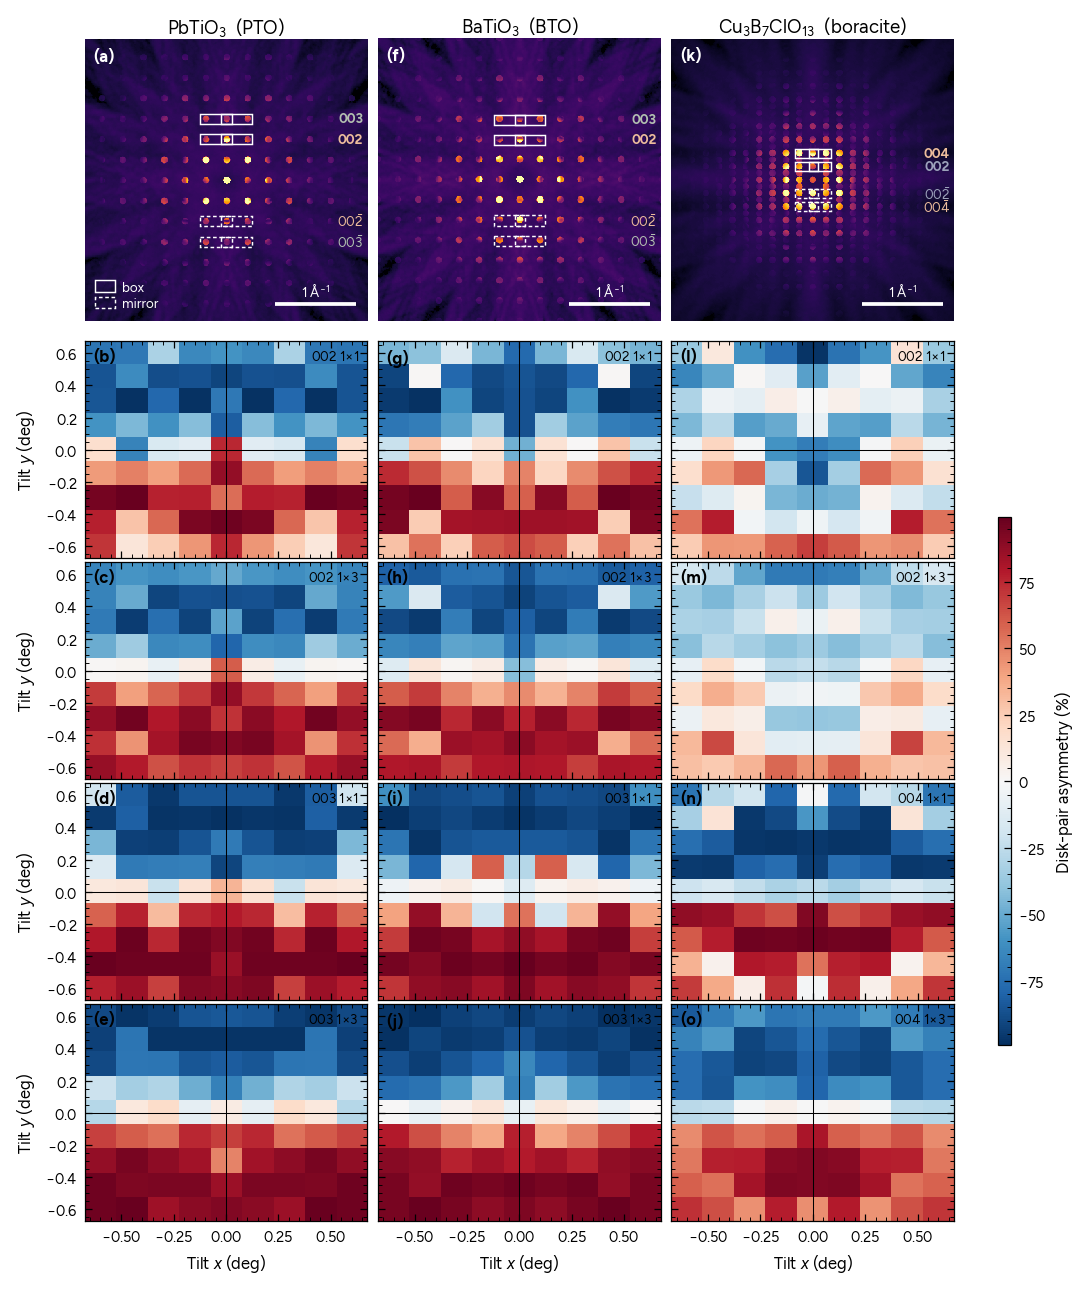

In [6]:
grid_figure(raw=True)

### Correctly oriented version
What the sims would give had every structure been polarised the same way along the measured
axis (as PTO, +x). From `polarisation_direction.py`: BTO and boracite were simulated with P
reversed relative to PTO (lab P_x = +38.2, -17.9, -0.71 uC/cm2), so both are mirrored,
v(ty, tx) -> -v(-ty, tx); PTO is unchanged. Identical to the main grid figure, which already flips both. Saved with the `aligned_` prefix.

saved figures/aligned_disks_intensity_grid.{pdf,png}


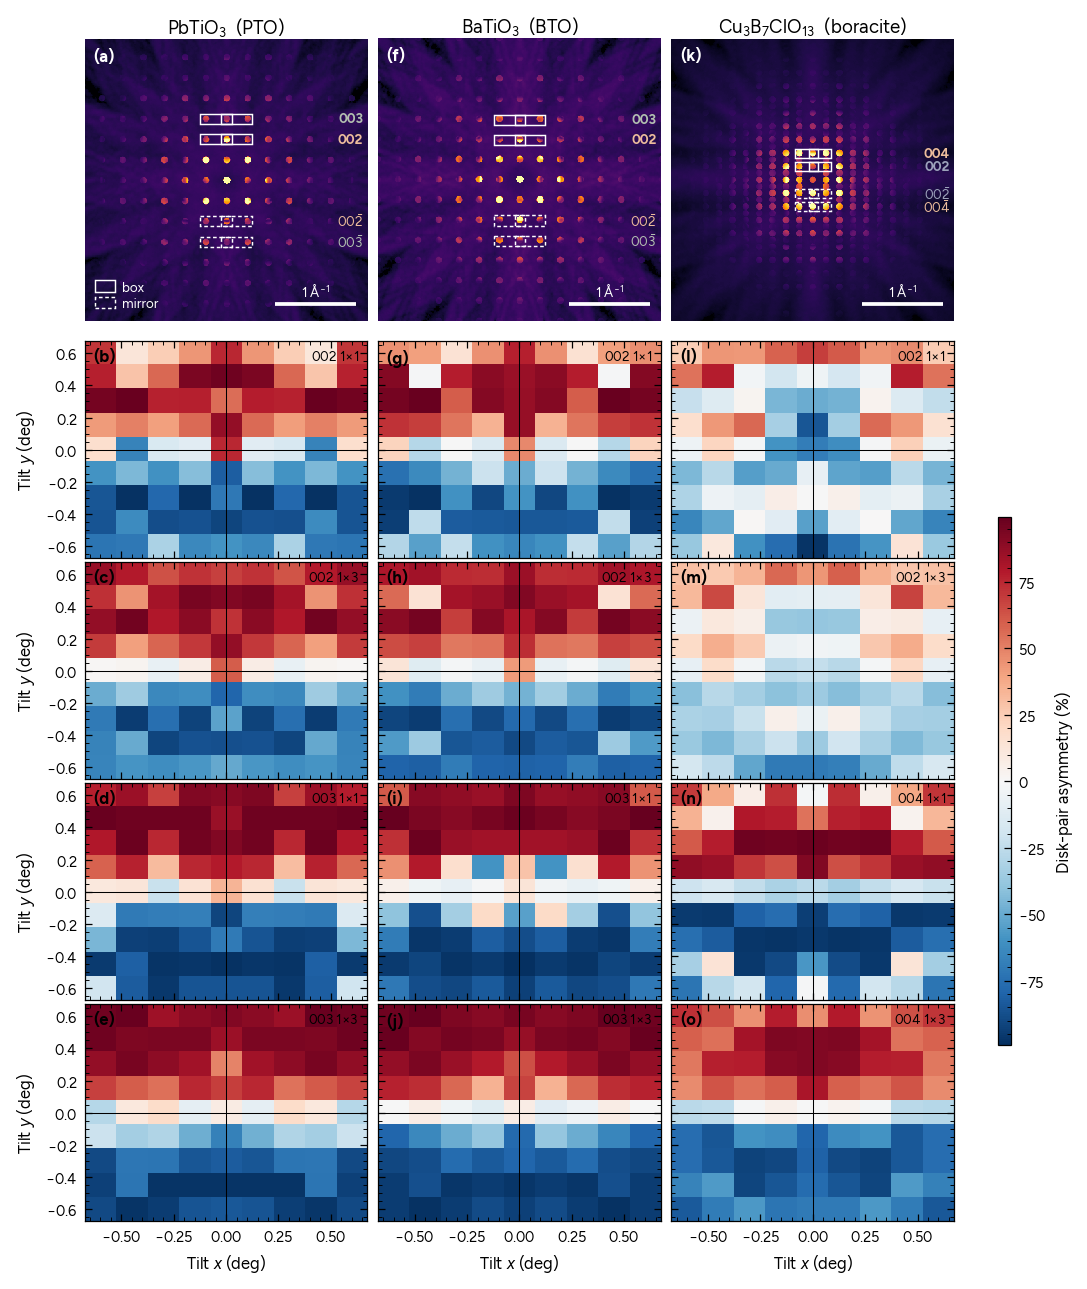

In [7]:
grid_figure(aligned=True)

saved figures/corrected_final/corrected_final_disks_intensity_grid.{pdf,png}


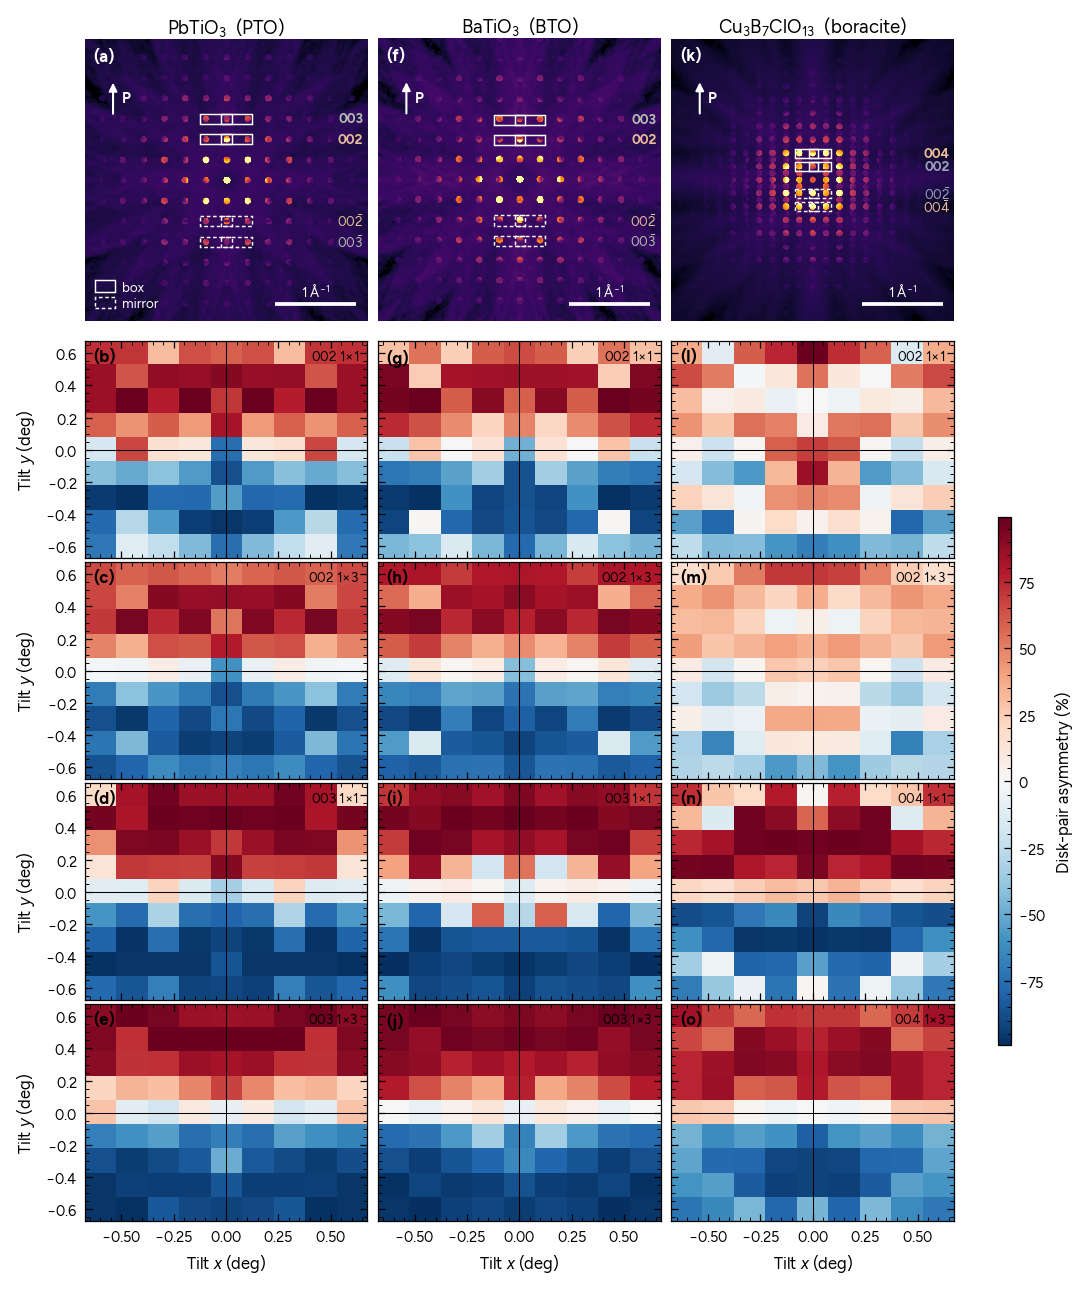

In [8]:
grid_figure(final=True)